In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = (
    "https://raw.githubusercontent.com/"
    "mwaskom/seaborn-data/master/titanic.csv"
)

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
# Dataset dimensions
print("Rows and columns:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

# First five records
display(df.head())

# Summary statistics for numeric columns
display(df.describe())

# Summary of categorical columns
display(df.describe(include="object"))

Rows and columns: (891, 15)

Column names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone  

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


In [3]:
# Count missing values
missing_counts = df.isnull().sum()

# Calculate missing percentages
missing_percent = (
    df.isnull().mean() * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing Count": missing_counts,
    "Missing Percentage": missing_percent
})

display(
    missing_summary[
        missing_summary["Missing Count"] > 0
    ].sort_values(
        "Missing Count", ascending=False
    )
)

# Check exact duplicate rows
print("Duplicate rows:", df.duplicated().sum())

,Missing Count,Missing Percentage
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


Duplicate rows: 107


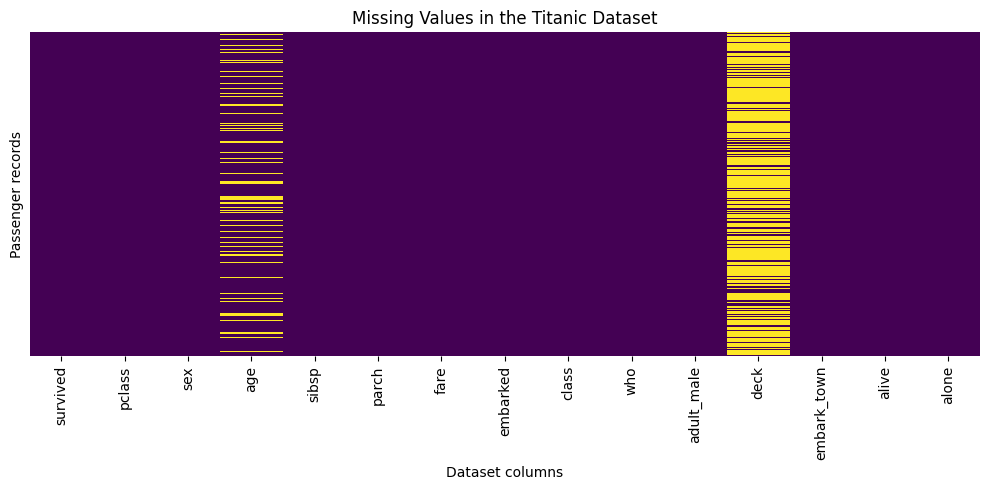

In [4]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in the Titanic Dataset")
plt.xlabel("Dataset columns")
plt.ylabel("Passenger records")
plt.tight_layout()
plt.show()

In [5]:
# Preserve the original dataset
clean_df = df.copy()

# Keep relevant columns for this EDA
selected_columns = [
    "survived",
    "pclass",
    "sex",
    "age",
    "sibsp",
    "parch",
    "fare",
    "embarked"
]

clean_df = clean_df[selected_columns].copy()

# Fill missing age values with the median
clean_df["age"] = clean_df["age"].fillna(
    clean_df["age"].median()
)

# Fill missing embarkation codes with the mode
clean_df["embarked"] = clean_df["embarked"].fillna(
    clean_df["embarked"].mode()[0]
)

# Verify cleaning
print("Missing values after cleaning:")
print(clean_df.isnull().sum())

print("\nCleaned dataset shape:", clean_df.shape)

display(clean_df.head())

Missing values after cleaning:
survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64

Cleaned dataset shape: (891, 8)


,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [6]:
# Numeric summaries
display(clean_df.describe().round(2))

# Survival counts
print("Survival counts:")
print(clean_df["survived"].value_counts())

# Survival percentages
print("\nSurvival percentages:")
print(
    (clean_df["survived"].value_counts(normalize=True) * 100)
    .round(2)
)

# Passenger counts by class
print("\nPassenger counts by class:")
print(clean_df["pclass"].value_counts().sort_index())

# Average age and fare by survival outcome
display(
    clean_df.groupby("survived")[["age", "fare"]]
    .mean()
    .round(2)
)

,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,891.00,891.00,891.00,891.00
mean,0.38,2.31,29.36,0.52,0.38,32.20
std,0.49,0.84,13.02,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,22.00,0.00,0.00,7.91
50%,0.00,3.00,28.00,0.00,0.00,14.45
75%,1.00,3.00,35.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


Survival counts:
survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
survived
0    61.62
1    38.38
Name: proportion, dtype: float64

Passenger counts by class:
pclass
1    216
2    184
3    491
Name: count, dtype: int64


,age,fare
survived,,
0,30.03,22.12
1,28.29,48.40


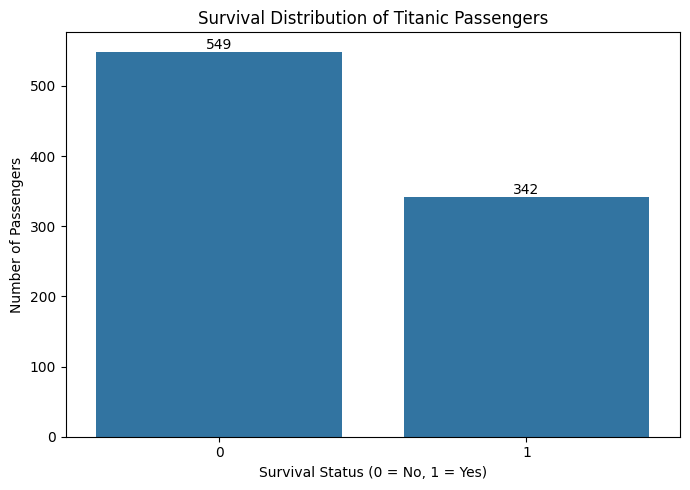

In [7]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=clean_df,
    x="survived"
)

ax.set_title("Survival Distribution of Titanic Passengers")
ax.set_xlabel("Survival Status (0 = No, 1 = Yes)")
ax.set_ylabel("Number of Passengers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

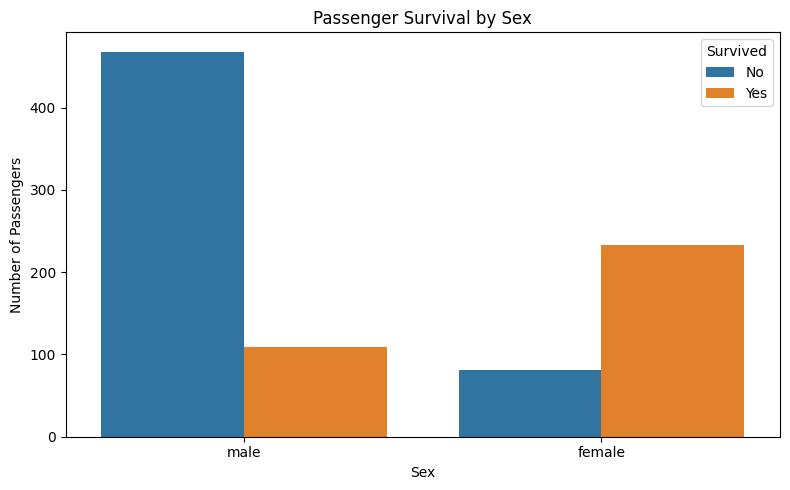

In [8]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=clean_df,
    x="sex",
    hue="survived"
)

ax.set_title("Passenger Survival by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Number of Passengers")
ax.legend(
    title="Survived",
    labels=["No", "Yes"]
)

plt.tight_layout()
plt.show()

In [9]:
sex_survival = (
    clean_df.groupby("sex")["survived"]
    .mean()
    .mul(100)
    .round(2)
)

print("Survival rate by sex (%):")
print(sex_survival)

Survival rate by sex (%):
sex
female    74.20
male      18.89
Name: survived, dtype: float64


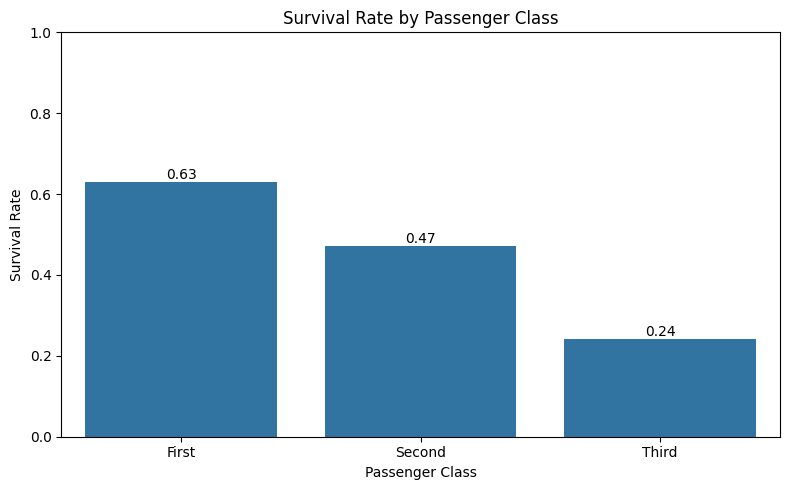

In [10]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=clean_df,
    x="pclass",
    y="survived",
    errorbar=None
)

ax.set_title("Survival Rate by Passenger Class")
ax.set_xlabel("Passenger Class")
ax.set_ylabel("Survival Rate")

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["First", "Second", "Third"])

ax.set_ylim(0, 1)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f"
    )

plt.tight_layout()
plt.show()

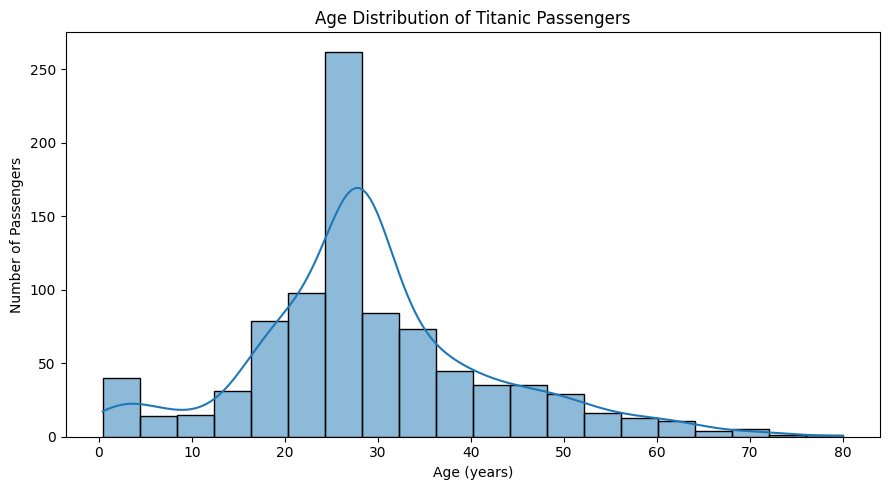

In [11]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=clean_df,
    x="age",
    bins=20,
    kde=True
)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age (years)")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

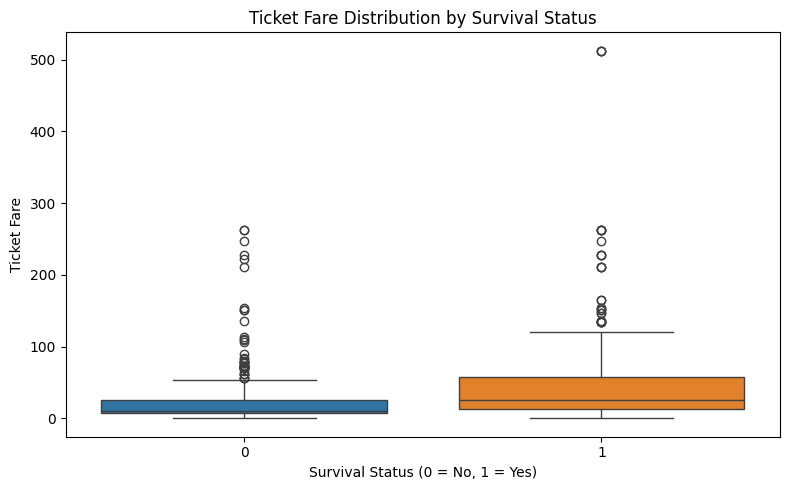

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clean_df,
    x="survived",
    y="fare",
    hue="survived",
    legend=False
)

plt.title("Ticket Fare Distribution by Survival Status")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Ticket Fare")

plt.tight_layout()
plt.show()

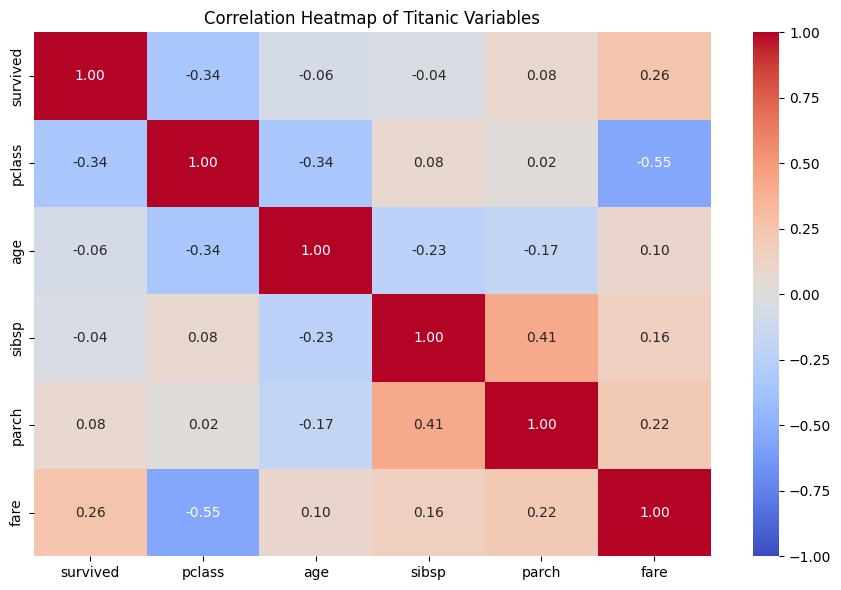

In [13]:
numeric_columns = [
    "survived",
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare"
]

correlation = clean_df[numeric_columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Titanic Variables")
plt.tight_layout()
plt.show()

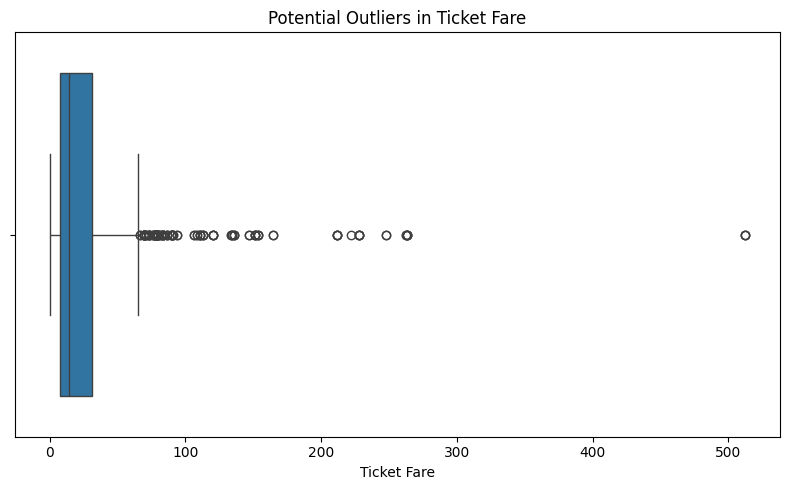

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=clean_df, x="fare")

plt.title("Potential Outliers in Ticket Fare")
plt.xlabel("Ticket Fare")

plt.tight_layout()
plt.show()

In [15]:
# Survival rate by class and sex
class_sex_survival = (
    clean_df.groupby(["pclass", "sex"])["survived"]
    .agg(["count", "mean"])
    .reset_index()
)

class_sex_survival["survival_rate_percent"] = (
    class_sex_survival["mean"] * 100
).round(2)

display(class_sex_survival)

,pclass,sex,count,mean,survival_rate_percent
0,1,female,94,0.968085,96.81
1,1,male,122,0.368852,36.89
2,2,female,76,0.921053,92.11
3,2,male,108,0.157407,15.74
4,3,female,144,0.500000,50.00
5,3,male,347,0.135447,13.54


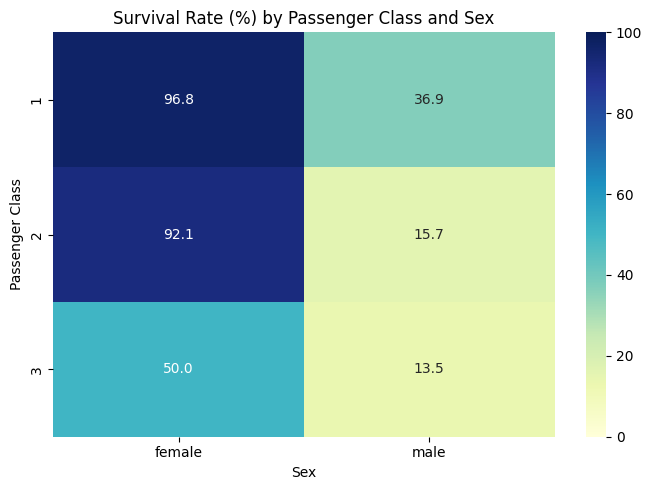

In [16]:
pivot_table = clean_df.pivot_table(
    index="pclass",
    columns="sex",
    values="survived",
    aggfunc="mean"
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    pivot_table * 100,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100
)

plt.title("Survival Rate (%) by Passenger Class and Sex")
plt.xlabel("Sex")
plt.ylabel("Passenger Class")

plt.tight_layout()
plt.show()

In [18]:
plt.tight_layout()

plt.savefig(
    "survival_by_sex.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

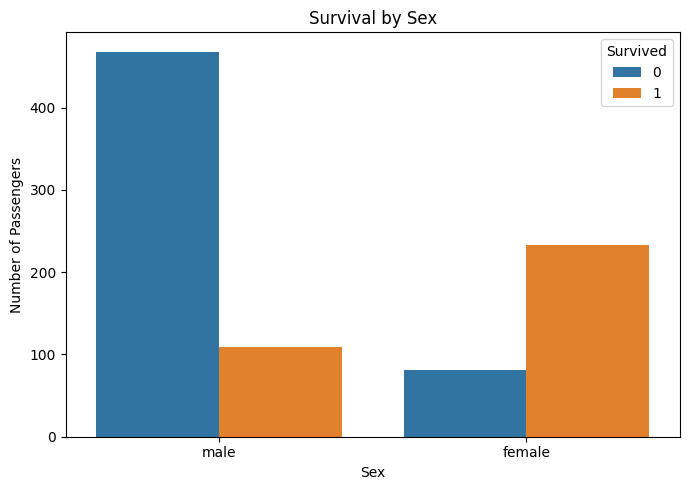

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create the chart
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="sex", hue="survived")

plt.title("Survival by Sex")
plt.xlabel("Sex")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived")

# Adjust layout and save
plt.tight_layout()
plt.savefig(
    r"C:\Users\Kavya m\OneDrive\Desktop\yuva_2\survival_by_sex.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the chart
plt.show()